# 07 · The pyramid wavefront sensor (exploratory)

The pyramid sensor puts a four-sided glass pyramid at the focal plane. Each face sends its quarter of the focal plane to a different place, so a pupil-plane camera sees four images of the pupil. A wavefront slope moves light between the faces, and normalised differences of the four images measure it. It is more sensitive than a Shack–Hartmann near the diffraction limit, but its linear range is small, which is why the beam is usually swept around the pyramid tip (modulation).

`pwfs_forward.py` is a compact Fourier-optics model of this. It is not used in the closed loops of this repository.

**Check against theory:** for a pure tilt $t$ and circular modulation of radius $r$, geometric optics gives $S_x = \tfrac{2}{\pi}\arcsin(t/r)$ for $|t| < r$.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIGURES = ROOT / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from pwfs_forward import make_pwfs_grid, pwfs_intensity, pwfs_signal_maps_from_intensity, pyramid_phase_mask

## 1. Four pupil images

A 64-pixel pupil on a 256-pixel grid. Tilts and the modulation radius are given in the module's units: the phase of a tilt $t$ is $2\pi t\,x$ with $x$ in pupil radii, which moves the focal spot by $2t\,\lambda/D$.

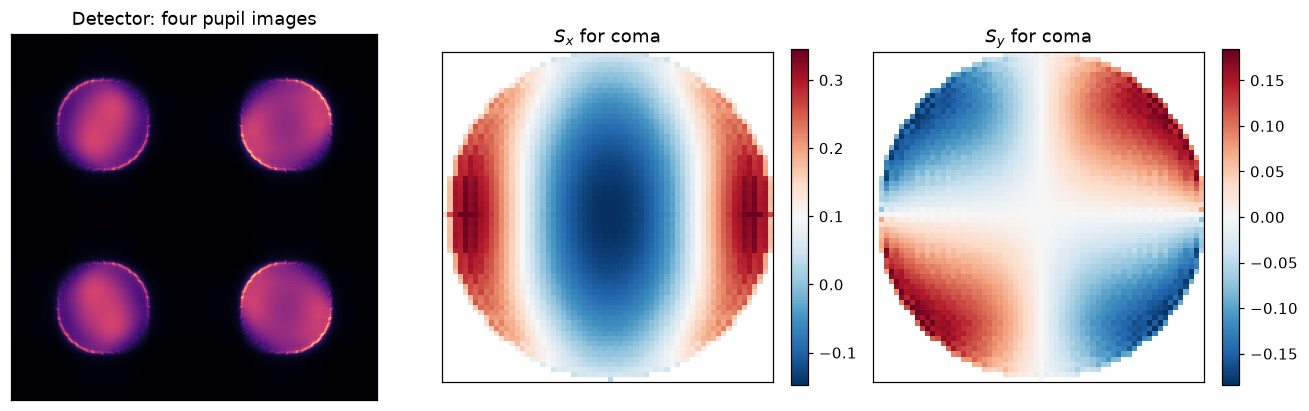

In [2]:
N_FFT, N_PUPIL, SEPARATION = 256, 64, 64
x, y, rho, theta, pupil = make_pwfs_grid(n_fft=N_FFT, n_pupil=N_PUPIL)
pyramid = pyramid_phase_mask(n_fft=N_FFT, separation=SEPARATION)


def intensity(phase, modulation=0.0, points=48):
    return pwfs_intensity(phase, pupil, x, y, pyramid_mask=pyramid, separation=SEPARATION,
                          modulation_radius=modulation, n_modulation_points=points)


coma = np.where(pupil, 0.6 * (3 * rho**3 - 2 * rho) * np.cos(theta), 0.0)
image = intensity(coma, modulation=1.0)
Sx, Sy, total, valid = pwfs_signal_maps_from_intensity(image, n_pupil=N_PUPIL, separation=SEPARATION)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].imshow(image, origin="lower", cmap="magma")
axes[0].set_title("Detector: four pupil images")
for ax, signal, name in [(axes[1], Sx, "$S_x$"), (axes[2], Sy, "$S_y$")]:
    shown = ax.imshow(np.where(valid, signal, np.nan), origin="lower", cmap="RdBu_r")
    fig.colorbar(shown, ax=ax, fraction=0.046)
    ax.set_title(f"{name} for coma")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
plt.tight_layout()
fig.savefig(FIGURES / "07_pyramid_images.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Check: tilt response and modulation

For each modulation radius the mean $S_x$ over the pupil is measured against the applied tilt, after subtracting the zero-tilt reference. Without modulation the response saturates within a fraction of $\lambda/D$. With modulation it follows the $\tfrac{2}{\pi}\arcsin(t/r)$ shape up to $t = r$, trading sensitivity (slope) for range. Geometric optics ignores diffraction, so the agreement should improve as the modulation radius grows compared with $\lambda/D$; the second cell tests that.

r = 1.0: largest difference from (2/pi) arcsin(t/r) for t < r: 0.129


r = 2.5: largest difference from (2/pi) arcsin(t/r) for t < r: 0.082


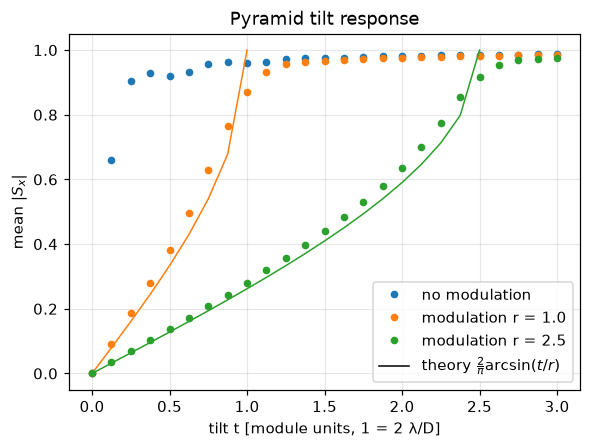

In [3]:
tilts = np.linspace(0, 3.0, 25)
fig, ax = plt.subplots(figsize=(6, 4.2))
for modulation, color in [(0.0, "C0"), (1.0, "C1"), (2.5, "C2")]:
    reference = pwfs_signal_maps_from_intensity(intensity(np.zeros_like(x), modulation), n_pupil=N_PUPIL, separation=SEPARATION)
    signal = []
    for t in tilts:
        Sx, _, _, valid = pwfs_signal_maps_from_intensity(intensity(2 * np.pi * t * x * pupil, modulation), n_pupil=N_PUPIL, separation=SEPARATION)
        signal.append(np.mean((Sx - reference[0])[valid]))
    signal = np.abs(signal)
    label = "no modulation" if modulation == 0 else f"modulation r = {modulation}"
    ax.plot(tilts, signal, "o", ms=4, color=color, label=label)
    if modulation > 0:
        inside = tilts <= modulation
        theory = 2 / np.pi * np.arcsin(tilts[inside] / modulation)
        ax.plot(tilts[inside], theory, "-", color=color, lw=1)
        print(f"r = {modulation}: largest difference from (2/pi) arcsin(t/r) for t < r: {np.max(np.abs(signal[inside] - theory)):.3f}")
ax.plot([], [], "k-", lw=1, label=r"theory $\frac{2}{\pi}\arcsin(t/r)$")
ax.set(xlabel="tilt t [module units, 1 = 2 λ/D]", ylabel=r"mean $|S_x|$", title="Pyramid tilt response")
ax.legend()
plt.show()

In [4]:
print("modulation radius   largest |simulation - theory| for t < r   small-tilt slope / theory")
for modulation, points in [(1.0, 48), (2.5, 48), (5.0, 96), (8.0, 128)]:
    reference = pwfs_signal_maps_from_intensity(intensity(np.zeros_like(x), modulation, points), n_pupil=N_PUPIL, separation=SEPARATION)
    t_values = np.linspace(0, modulation, 11)[1:-1]
    measured = []
    for t in t_values:
        Sx, _, _, valid = pwfs_signal_maps_from_intensity(intensity(2 * np.pi * t * x * pupil, modulation, points), n_pupil=N_PUPIL, separation=SEPARATION)
        measured.append(abs(np.mean((Sx - reference[0])[valid])))
    theory = 2 / np.pi * np.arcsin(t_values / modulation)
    print(f"{modulation:5.1f} = {2 * modulation:4.0f} lambda/D {np.max(np.abs(np.array(measured) - theory)):30.3f} {measured[0] / theory[0]:26.3f}")

modulation radius   largest |simulation - theory| for t < r   small-tilt slope / theory


  1.0 =    2 lambda/D                          0.094                      1.159


  2.5 =    5 lambda/D                          0.063                      1.072


  5.0 =   10 lambda/D                          0.032                      1.036


  8.0 =   16 lambda/D                          0.015                      1.016


## Summary

- The pyramid turns slopes into intensity differences between four pupil images; the $S_x$ and $S_y$ maps of coma show its slope pattern directly.
- Without modulation the tilt response saturates almost immediately; modulation widens the linear range at the cost of sensitivity.
- The response converges to the geometric-optics law $\tfrac{2}{\pi}\arcsin(t/r)$ as the modulation grows: the largest difference falls from 0.09 at 2 λ/D to 0.015 at 16 λ/D. At small modulation the pyramid is more sensitive than geometric optics predicts, which is a diffraction effect.
- This model is exploratory; closing a loop with it, as the archived notebook 08 does, is left out of the tutorial series.